<a href="https://colab.research.google.com/github/shubhamjadoun5-source/basic_project/blob/main/project2unlox.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df=pd.read_csv('/content/AB_NYC_2019.csv')


In [ ]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [ ]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [ ]:
#Outlier Treatment boxplot
plt.figure(figsize=(14, 5))

<Figure size 1400x500 with 0 Axes>

<Figure size 1400x500 with 0 Axes>

Text(0.5, 0, 'Price ($)')

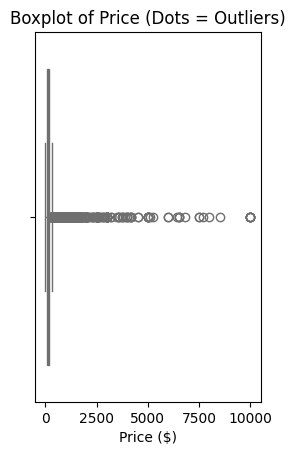

In [ ]:
plt.subplot(1, 2, 1)
sns.boxplot(x=df['price'], color='skyblue')
plt.title('Boxplot of Price (Dots = Outliers)')
plt.xlabel('Price ($)')

In [ ]:
# Histogram
plt.subplot(1, 2, 2)

Text(0, 0.5, 'Count (Log Scale)')

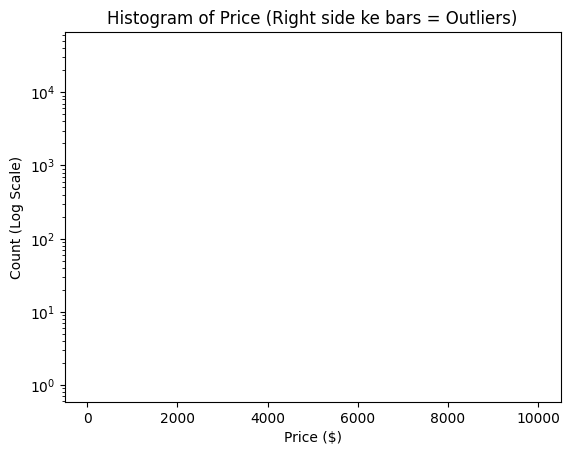

In [ ]:
sns.histplot(df['price'], bins=50, color='salmon', log_scale=(False, True))
plt.title('Histogram of Price (Right side ke bars = Outliers)')
plt.xlabel('Price ($)')
plt.ylabel('Count (Log Scale)')

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X = df.drop('price', axis=1) # Everything except 'price' goes into X
y = df['price']              # Only the 'price' column goes into y

# Split the data into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# check the result
print("Total data rows:", len(df))
print("Training data (X_train) rows:", len(X_train))
print("Testing data (X_test) rows:", len(X_test))

Total data rows: 48895
Training data (X_train) rows: 39116
Testing data (X_test) rows: 9779


In [ ]:
from sklearn.linear_model import LinearRegression

# Keep only numeric columns for modeling
numeric_cols = ['minimum_nights', 'number_of_reviews', 'calculated_host_listings_count', 'availability_365', 'latitude', 'longitude']

# Initialize the Linear Regression model
model = LinearRegression()

# Train the model using only the numeric features
model.fit(X_train[numeric_cols], y_train)

# Make predictions using the testing data
predictions = model.predict(X_test[numeric_cols])

# Print the predicted values
print(predictions)

[158.11008285 112.78690479 171.97214606 ...  44.85021761 159.82800606
 221.11362782]


In [ ]:
# Create a DataFrame to compare actual and predicted prices
results_df = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': np.round(predictions, 2),
    'Difference (Error)': np.round(y_test.values - predictions, 2)
})

# Display the first 10 rows of the comparison table
results_df.head(10)

,Actual Price,Predicted Price,Difference (Error)
0,89,158.11,-69.11
1,30,112.79,-82.79
2,120,171.97,-51.97
3,470,252.90,217.10
4,199,133.14,65.86
5,170,97.09,72.91
6,90,142.70,-52.70
7,60,83.91,-23.91
8,150,158.31,-8.31
9,74,54.33,19.67


In [ ]:
from sklearn.metrics import r2_score, mean_squared_error

# Calculate metrics
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

# Print the evaluation metrics
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Mean Squared Error (MSE): 42540.85
R-squared (R2) Score: 0.0384


In [ ]:
# Fill reviews_per_month with 0 where number_of_reviews is 0
df['reviews_per_month'] = df.apply(
    lambda row: 0 if row['number_of_reviews'] == 0 else row['reviews_per_month'],
    axis=1
)

# For any remaining missing values in reviews_per_month (if any), fill with mean
df['reviews_per_month'] = df['reviews_per_month'].fillna(df['reviews_per_month'].mean())

# Fill missing values in text columns with a placeholder
df['name'] = df['name'].fillna('Unknown')
df['host_name'] = df['host_name'].fillna('Unknown')

# Check if there are any remaining null values
display(df.isnull().sum())

,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0
